# Loan Default Risk — Analysis

Predict whether a loan will default from borrower and loan features, then score pending applicants. Three models are compared with cross-validated ROC AUC; the best is evaluated on a held-out slice and used to rank new requests.

*Everything here reuses the functions in `loan_default.py`.*

In [ ]:
import pandas as pd, loan_default as L
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

df = L.engineer_features(L.load_data())
X, y = df[L.RAW_CATEGORICAL + L.NUMERIC], df[L.TARGET]
df[L.RAW_NUMERIC + L.ENGINEERED].describe().round(2)

       person_age  person_income  person_emp_length  loan_amnt  loan_int_rate  loan_percent_income  cb_person_cred_hist_length  loan_to_income  credit_history_ratio  income_per_age
count    24435.00       24435.00           24435.00   24435.00       24435.00             24435.00                    24435.00        24435.00              24435.00        24435.00
mean        27.73       66156.13               4.75    9583.82          11.00                 0.17                        5.80            0.17                  0.19         2419.96
std          6.25       65688.50               3.98    6330.12           3.08                 0.11                        4.06            0.11                  0.09         1727.71
min         20.00        4000.00               0.00     500.00           5.42                 0.00                        2.00            0.00                  0.02           97.56
25%         23.00       38400.00               2.00    5000.00           8.49                 0

## 1. The target is imbalanced

About 1 in 5 loans defaults, so accuracy alone is misleading and **recall** (catching real defaults) matters.

## 2. Compare three models — 5-fold cross-validated ROC AUC

In [ ]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
fitted, cv = {}, {}
for name, model in L.build_models().items():
    cv[name] = cross_val_score(model, Xtr, ytr, cv=5, scoring='roc_auc', n_jobs=-1).mean()
    fitted[name] = model.fit(Xtr, ytr)
pd.Series(cv, name='CV ROC AUC').sort_values(ascending=False).round(3)

Random Forest          0.929
Gradient Boosting      0.928
Logistic Regression    0.877

## 3. Held-out performance

The full scorecard on the 20% test set the models never saw.

In [ ]:
rows = []
for name, model in fitted.items():
    p = model.predict(Xte); pr = model.predict_proba(Xte)[:, 1]
    rows.append([name, accuracy_score(yte,p), precision_score(yte,p),
                 recall_score(yte,p), f1_score(yte,p), roc_auc_score(yte,pr)])
pd.DataFrame(rows, columns=['model','accuracy','precision','recall','F1','ROC_AUC']).set_index('model').round(3)

                     accuracy  precision  recall     F1  ROC_AUC
model                                                           
Logistic Regression     0.823      0.565   0.786  0.657    0.879
Random Forest           0.927      0.893   0.753  0.817    0.933
Gradient Boosting       0.928      0.945   0.711  0.811    0.932

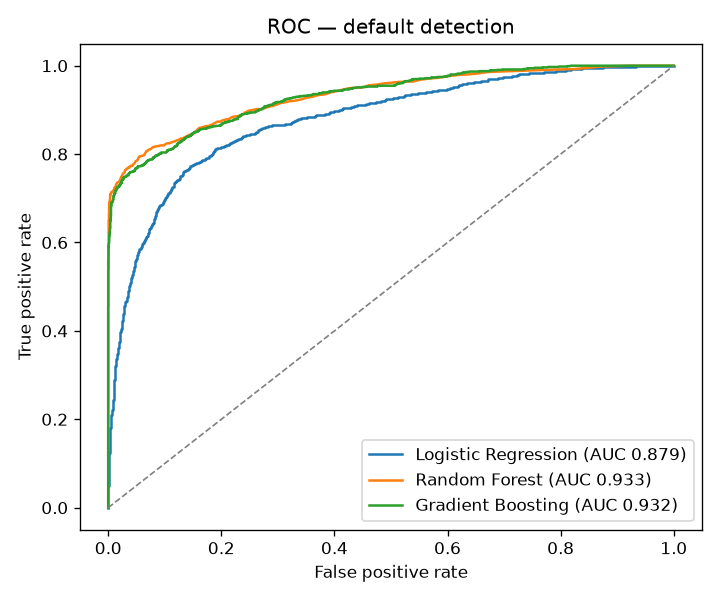

In [ ]:
# ROC curves for all three models
plot_roc(fitted, Xte, yte)

## 4. What drives the prediction

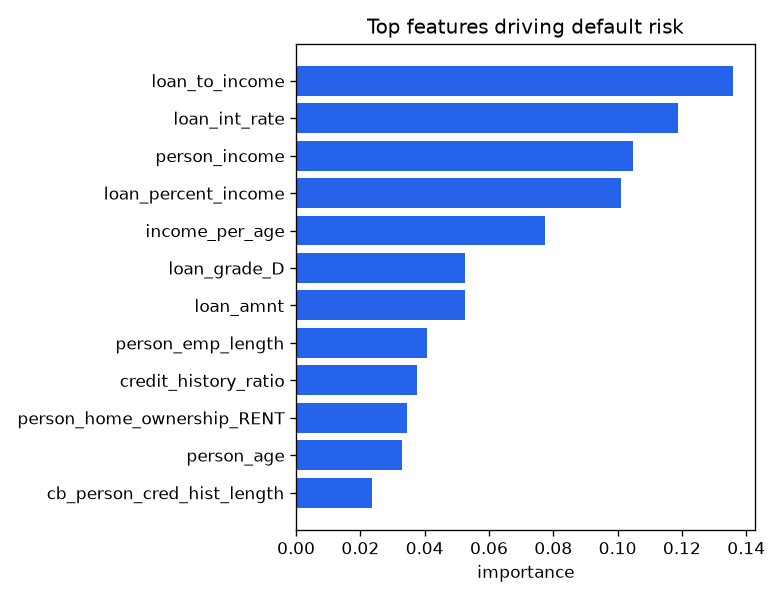

In [ ]:
plot_feature_importance(fitted['Random Forest'])

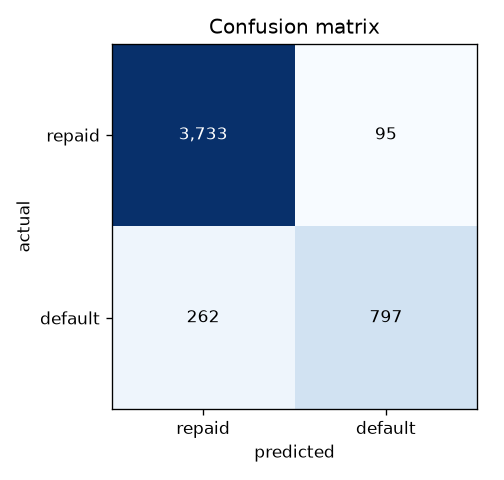

In [ ]:
plot_confusion(fitted['Random Forest'], Xte, yte)

## 5. Score pending applicants

Turn the probability into an action: **approve** (<20%), **review** (20-50%), **DECLINE** (>=50%).

In [ ]:
L.score_requests(fitted[max(cv, key=cv.get)], df)[['borrower','default_risk','action']]

          borrower default_risk  action
       Amara Patel       100.0% DECLINE
     Elena Petrova        99.6% DECLINE
    Hiroshi Tanaka        96.8% DECLINE
 Mohammed Al-Farsi        80.4% DECLINE
          Chen Wei        28.8%  review
       Sofia Rossi        18.0% approve
     Liam O'Connor        16.8% approve
Alejandro Gonzalez         6.0% approve
      Fatima Ahmed         3.2% approve
    Johan Svensson         1.2% approve

---
**Takeaway.** A balanced Random Forest reaches ROC AUC ~0.93 and catches ~75% of real defaults while keeping false alarms low — enough to triage applications, auto-flagging clear declines and routing borderline cases to a human.